In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

from lightgbm import LGBMClassifier

In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../Edge-IIoTset_ML-112.csv')

In [4]:
df.head(10)

,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,dns_4,dns_5,dns_6,dns_7,mqtt1_0,mqtt1_1,mqtt1_2,mqtt2_0,mqtt3_0,mqtt3_2
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,87.0,3.794211e+09,48707.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,59.0,6.828863e+08,19031.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,194.0,2.337571e+09,39685.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,16724.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,6.196863e+08,26682.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6,0.0,0.0,9047.0,41365.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,365851987.0,3.658520e+08,56450.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,261.0,2.367878e+09,44524.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152245 entries, 0 to 152244
Data columns (total 73 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   arp.opcode               152245 non-null  float64
 1   arp.hw.size              152245 non-null  float64
 2   icmp.checksum            152245 non-null  float64
 3   icmp.seq_le              152245 non-null  float64
 4   icmp.transmit_timestamp  152245 non-null  float64
 5   http.content_length      152245 non-null  float64
 6   http.response            152245 non-null  float64
 7   tcp.ack                  152245 non-null  float64
 8   tcp.ack_raw              152245 non-null  float64
 9   tcp.checksum             152245 non-null  float64
 10  tcp.connection.fin       152245 non-null  float64
 11  tcp.connection.rst       152245 non-null  float64
 12  tcp.connection.syn       152245 non-null  float64
 13  tcp.connection.synack    152245 non-null  float64
 14  tcp.

In [6]:
print(df['Attack_type'].value_counts())

Attack_type
Normal                   24141
DDoS_UDP                 14498
DDoS_ICMP                13096
DDoS_HTTP                10495
SQL_injection            10282
DDoS_TCP                 10247
Uploading                10221
Vulnerability_scanner    10062
Password                  9972
Backdoor                  9865
Ransomware                9689
XSS                       9545
Port_Scanning             8921
Fingerprinting             853
MITM                       358
Name: count, dtype: int64


In [7]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [8]:
print(df['Attack_type'].value_counts())

Attack_type
0     24141
13    14498
14    13096
5     10495
4     10282
6     10247
2     10221
9     10062
7      9972
10     9865
3      9689
11     9545
8      8921
12      853
1       358
Name: count, dtype: int64


In [9]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [10]:
# Apply the Chi-Squared test
chi_selector = SelectKBest(chi2, k='all')  # Set k to the desired number of features
X_kbest = chi_selector.fit_transform(X, y)

In [11]:
# Get the scores for each feature
chi_scores = chi_selector.scores_

# Combine scores with feature names
chi_scores = pd.DataFrame({'feature': X.columns, 'score': chi_scores})

# Sort the features by their scores
chi_scores = chi_scores.sort_values(by='score', ascending=False)

print(chi_scores)

                    feature         score
7                   tcp.ack  7.698778e+13
8               tcp.ack_raw  5.919730e+13
18                  tcp.seq  1.473468e+12
4   icmp.transmit_timestamp  1.133377e+12
20               udp.stream  1.816126e+11
..                      ...           ...
50                  http3_1  1.413069e+01
49                  http3_0  1.413069e+01
53                  http3_4  1.413069e+01
64                    dns_7  5.306491e+00
25   dns.retransmit_request  5.306491e+00

[71 rows x 2 columns]


In [12]:
selected_features = chi_scores['feature'].tolist()[:67]  # Select top k features

In [13]:
# Split the data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)

# Split the training data further into train (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

In [14]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (106571, 67)
X_val shape: (15225, 67)
X_test shape: (30449, 67)


In [15]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [16]:
# Initialize the LightGBM classifier
def light_gbm_model(_class_weight_dict):
    _model = LGBMClassifier(
        objective='multiclass',
        num_class=15,
        class_weight=_class_weight_dict,
        learning_rate=0.1,
        n_estimators=100,
        num_leaves=50,
        max_depth=10,
        reg_lambda=0,
        reg_alpha=0,
        random_state=42
    )
    return _model


class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)

class_weight_dict = dict(zip(np.unique(y_train), class_weights))

model = light_gbm_model(class_weight_dict)

In [17]:
# Train the model
model.fit(X_train, y_train, eval_set=(X_val, y_val), eval_metric=['multi_logloss', 'multi_error'])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008465 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2824
[LightGBM] [Info] Number of data points in the train set: 106571, number of used features: 58
[LightGBM] [Info] Start training from score -2.708050
[LightGBM] [Info] Start training from score -2.708050
[LightGBM] [Info] Start training from score -2.708050
[LightGBM] [Info] Start training from score -2.708050
[LightGBM] [Info] Start training from score -2.708050
[LightGBM] [Info] Start training from score -2.708050
[LightGBM] [Info] Start training from score -2.708050
[LightGBM] [Info] Start training from score -2.708050
[LightGBM] [Info] Start training from score -2.708050
[LightGBM] [Info] Start training from score -2.708050
[LightGBM] [Info] Start training from score -2.708050
[LightGBM] [Info] Start training from score -2.70805

LGBMClassifier(class_weight={0: 0.42072205444029925, 1: 28.41893333333333,
                             2: 0.9860837381448069, 3: 1.0615170078191145,
                             4: 0.9864944922706655, 5: 0.974586191129401,
                             6: 0.9907590759075907, 7: 1.0216757741347906,
                             8: 1.1367573333333334, 9: 1.0104868913857679,
                             10: 1.0280326050258042, 11: 1.0591433114688928,
                             12: 11.981000562113547, 13: 0.6950433705080545,
                             14: 0.7719180066637694},
               max_depth=10, num_class=15, num_leaves=50,
               objective='multiclass', random_state=42, reg_alpha=0,
               reg_lambda=0)

In [18]:
# Predict on the test set
y_pred = model.predict(X_test)

/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [19]:
y_pred_classes = y_pred

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))], zero_division=0))


Accuracy: 0.9645636966731256
Classification Report:
                       precision    recall  f1-score   support

               Normal       1.00      1.00      1.00      4837
                 MITM       1.00      1.00      1.00        80
            Uploading       0.95      0.89      0.92      1961
           Ransomware       0.97      0.98      0.98      2031
        SQL_injection       0.87      0.89      0.88      2076
            DDoS_HTTP       0.92      0.98      0.95      2191
             DDoS_TCP       1.00      1.00      1.00      2028
             Password       0.84      0.87      0.86      1998
        Port_Scanning       1.00      1.00      1.00      1793
Vulnerability_scanner       0.99      0.98      0.98      2034
             Backdoor       0.98      0.97      0.97      2013
                  XSS       0.96      0.91      0.94      1855
       Fingerprinting       0.97      0.94      0.95       177
             DDoS_UDP       1.00      1.00      1.00      2813
  

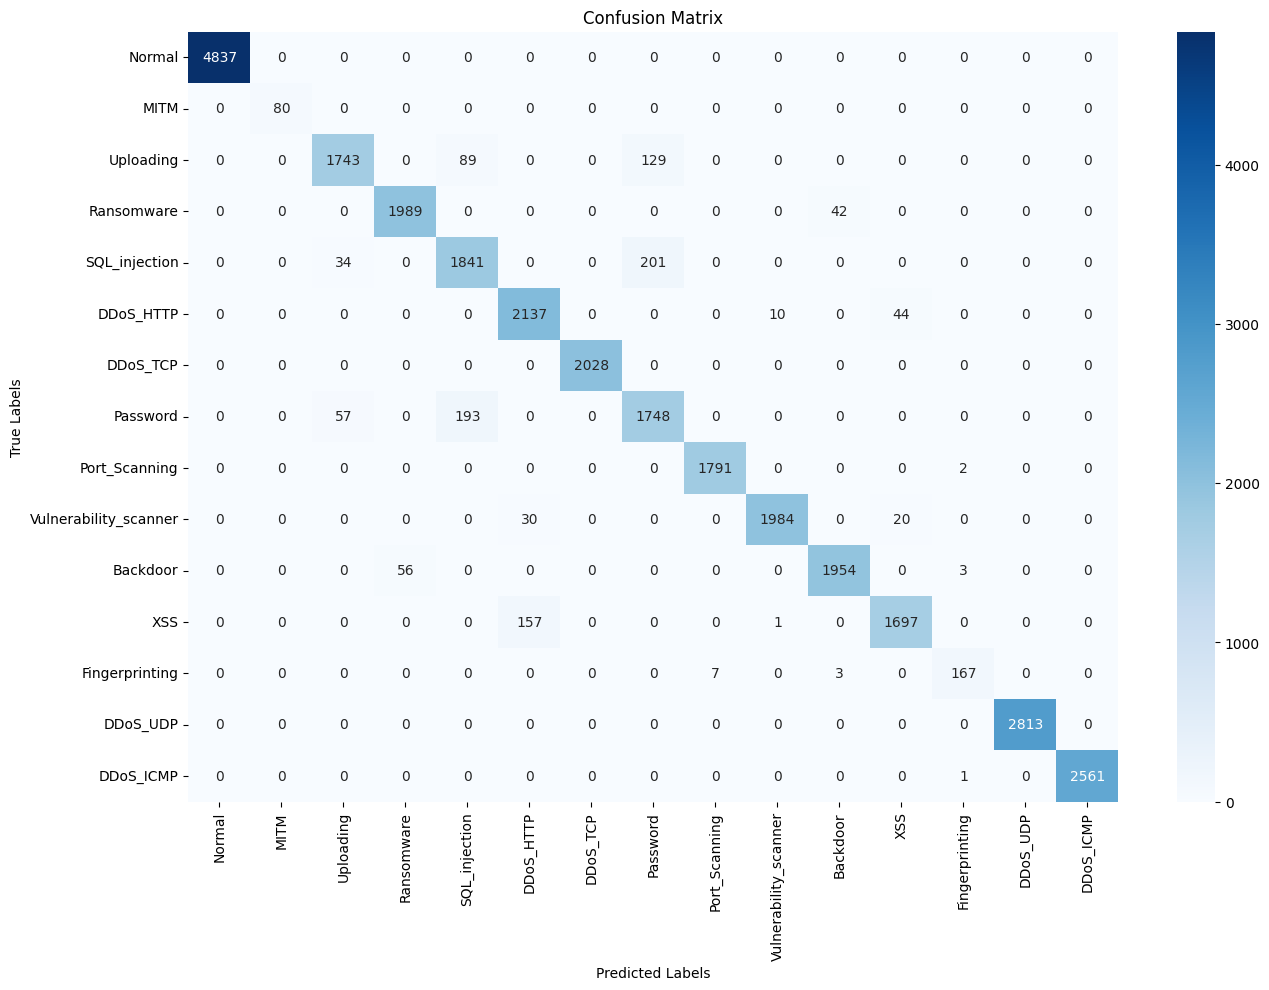

In [20]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

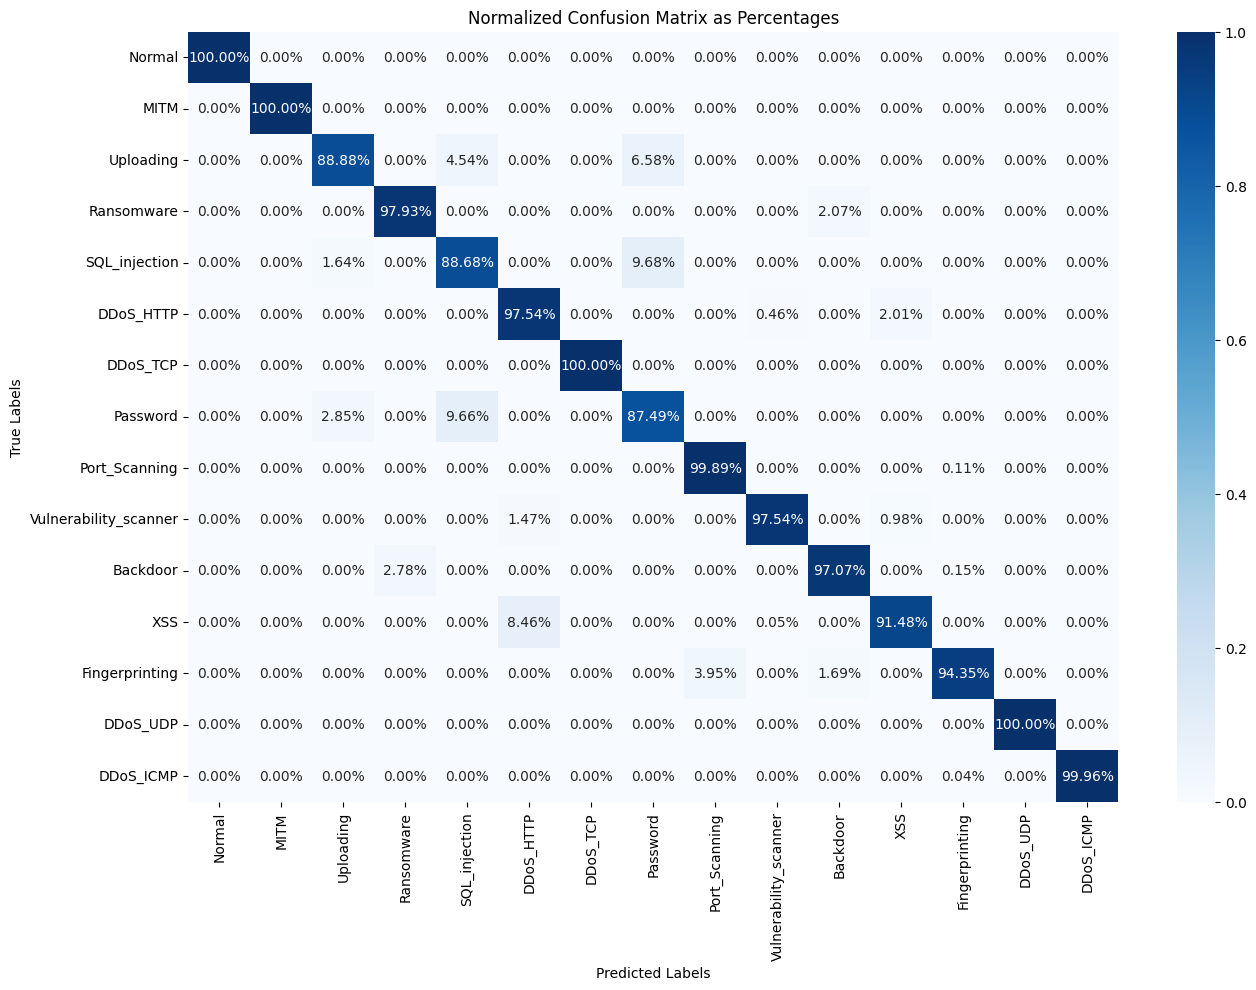

In [21]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()